<a href="https://colab.research.google.com/github/lcdf01/genai_tigs/blob/claude%2Fsoftware-testing-lab-avanzato-21f75f/genai_tigs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Torna in /content ed elimina eventuali cartelle/file residui
%cd /content
!rm -rf /content/genai_tigs /content/weights /content/data

# 2. Clona il branch della PR e spostati nella repository
!git clone -b claude/software-testing-lab-avanzato-21f75f https://github.com/lcdf01/genai_tigs.git
%cd /content/genai_tigs

# 3. Installa tutte le dipendenze (base + BigGAN + Stable Diffusion)
!pip install -q -r requirements.txt
!pip install -q pytorch-pretrained-biggan diffusers transformers accelerate gdown

# 4. Crea le directory per i pesi e verifica che la GPU T4 sia attiva
!mkdir -p weights/svhn weights/cifar10 weights/imagenet weights/sd
!python -c "import torch; print('CUDA disponibile:', torch.cuda.is_available(), '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Nessuna')"

/content
Cloning into 'genai_tigs'...
remote: Enumerating objects: 6279, done.
remote: Counting objects: 100% (328/328), done.
remote: Compressing objects: 100% (171/171), done.
remote: Total 6279 (delta 261), reused 180 (delta 151), pack-reused 5951 (from 1)
Receiving objects: 100% (6279/6279), 359.65 MiB | 36.87 MiB/s, done.
Resolving deltas: 100% (1467/1467), done.
Updating files: 100% (3934/3934), done.
/content/genai_tigs
CUDA disponibile: True | GPU: Tesla T4


In [ ]:
# 1. Rimuovi i file corrotti e il file letterale *.safetensors
!rm -rf weights/svhn/* weights/cifar10/* weights/imagenet/* weights/sd/*

# 2. Mostra la tabella dei pesi nel README.md per distinguere cartelle Drive e singoli file
!grep -E "weights/|drive\.google\.com" README.md

import os, subprocess, zipfile, tarfile, shutil, glob

# Pulisce i download errati precedenti
for sub in ["svhn", "cifar10", "imagenet", "sd"]:
    shutil.rmtree(f"weights/{sub}", ignore_errors=True)
    os.makedirs(f"weights/{sub}", exist_ok=True)

os.makedirs("/tmp/dl_weights", exist_ok=True)

items = [
    ("1vLS_9TT4ncrAfP3LVAOQzw-zdKUgoPBb", "weights/svhn"),
    ("13D8DXRQ41pNv29jZDuWKjjUXMaXlpeG1", "weights/svhn"),
    ("1sxG5En1Vc1pEFhedebO8fRcvbb1NNE_y", "weights/cifar10"),
    ("1dLYUewBnDfOh6qsy8REWFbb57pktKg6k", "weights/cifar10"),
    ("1iM9Sp7l7zc5o_B5ZukQ4RP8fmkScdFBw", "weights/imagenet"),
    ("1FauJR7XbPt_g0W4r-LPIbv7si79JHh4V", "weights/sd"),
]

for idx, (fid, target_dir) in enumerate(items):
    work_dir = f"/tmp/dl_weights/item_{idx}"
    shutil.rmtree(work_dir, ignore_errors=True)
    os.makedirs(work_dir, exist_ok=True)

    # Scarica mantenendo il nome originale del file su Drive
    subprocess.run(["gdown", "--fuzzy", f"https://drive.google.com/uc?id={fid}"], cwd=work_dir, check=False)

    for fname in os.listdir(work_dir):
        fpath = os.path.join(work_dir, fname)
        # Controlla se è uno zip/tar o un file .pth/.safetensors diretto
        if zipfile.is_zipfile(fpath):
            print(f"Estraggo ZIP {fname} -> {target_dir}")
            with zipfile.ZipFile(fpath, "r") as zf:
                zf.extractall(work_dir)
            os.remove(fpath)
        elif tarfile.is_tarfile(fpath):
            print(f"Estraggo TAR {fname} -> {target_dir}")
            with tarfile.open(fpath, "r:*") as tf:
                tf.extractall(work_dir)
            os.remove(fpath)

    # Sposta tutti i checkpoint estratti (anche da eventuali sottocartelle) in target_dir
    for root, _, files in os.walk(work_dir):
        for f in files:
            if f.endswith((".pth", ".pt", ".safetensors", ".bin")):
                src = os.path.join(root, f)
                dst = os.path.join(target_dir, f)
                shutil.move(src, dst)
                print(f"  -> Salvato: {dst} ({os.path.getsize(dst) / 1e6:.1f} MB)")

    classifier/         model.py, train.py, weights/
    vae/                tig_vae.py, model.py, train.py, weights/, samples/
    gan/                tig_gan.py (ImageNet: tig_biggan.py), train_cdcgan.py, weights/, samples/
Not in git: `weights/` (checkpoints from Google Drive), `data/` (test sets, downloaded or copied there) and `results/` (output of the runs).
| MNIST classifier, VAE, GAN | already in `legacy/mnist/*/weights/` | — |
| SVHN classifier | `weights/svhn/SVHN_vggnet.pth` | [Drive](https://drive.google.com/file/d/1vLS_9TT4ncrAfP3LVAOQzw-zdKUgoPBb/view?usp=sharing) |
| SVHN VAE | `weights/svhn/svhn_convend.pth` | [Drive](https://drive.google.com/file/d/13D8DXRQ41pNv29jZDuWKjjUXMaXlpeG1/view?usp=sharing) |
| CIFAR-10 classifier | `weights/cifar10/CIFAR10_cifar10_train.pynet.pth` | [Drive](https://drive.google.com/file/d/1sxG5En1Vc1pEFhedebO8fRcvbb1NNE_y/view?usp=sharing) |
| CIFAR-10 VAE | `weights/cifar10/cifar10_convend.pth` | [Drive](https://drive.google.com/file/d/1dLY

In [ ]:
!pytest

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/genai_tigs
plugins: typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3, langsmith-0.14.17
collected 63 items                                                             

tests/test_cli_runner.py ................s...                            [ 31%]
tests/test_core.py ........                                              [ 44%]
tests/test_imagenet.py 

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/genai_tigs_results', exist_ok=True)
!rm -rf results
!ln -s /content/drive/MyDrive/genai_tigs_results results

In [ ]:
# Esempio su MNIST (cambia --dataset in svhn, cifar10, imagenet_pizza, imagenet_teddy e --perturbation in low / high)
!pip install -q --upgrade "torchao>=0.16.0"

!python -m tig \
  --model sd \
  --dataset mnist \
  --mutation low \
  --seed 0 \
  --num-images 1 \
  --generations 5 \
  --out /content/drive/MyDrive/genai_tigs_results

In [ ]:
# Test VAE su MNIST con poche generazioni
!python -m tig --model vae --dataset mnist --mutation low --seed 42 --num-images 2 --generations 5

# Test GAN su SVHN con più generazioni
!python -m tig --model gan --dataset svhn --mutation high --seed 42 --num-images 2 --generations 10

# Test Stable Diffusion su MNIST (richiede più tempo anche con poche generazioni)
!python -m tig --model sd --dataset mnist --mutation low --seed 42 --num-images 1 --generations 2


In [ ]:
import pandas as pd
import os

file_path = 'results/gan_svhn_high_s0/summary.csv'

# Fallback se la cartella s0 non esiste (ad esempio se è stato usato il seed 42 di recente)
if not os.path.exists(file_path):
    file_path = 'results/gan_svhn_high_s42/summary.csv'
    print(f"File con seed 0 non trovato, visualizzo: {file_path}\n")

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    display(df)
else:
    print(f"Errore: impossibile trovare il file {file_path}")

File con seed 0 non trovato, visualizzo: results/gan_svhn_high_s42/summary.csv

Errore: impossibile trovare il file results/gan_svhn_high_s42/summary.csv


In [ ]:
import subprocess
import time
import re

# Definiamo le combinazioni principali per i modelli
test_cases = [
    ("vae", "mnist"), ("vae", "svhn"), ("vae", "cifar10"),
    ("gan", "mnist"), ("gan", "svhn"), ("gan", "cifar10"),
    ("sd", "mnist"), ("sd", "svhn"), ("sd", "cifar10"),
    ("sd", "imagenet_pizza"), ("sd", "imagenet_teddy")
]
mutations = ["low", "high"]

print("=== Inizio test combinati (Smoke Test Globale con verifica Misbehaviour) ===")
print("Nota: I parametri sono tenuti bassi per completare i test in tempi ragionevoli su Colab.\n")

for model, dataset in test_cases:
    for mutation in mutations:
        # Stable Diffusion richiede molta VRAM e tempo, riduciamo al minimo indispensabile
        num_images = 1 if model == 'sd' else 2
        generations = 2 if model == 'sd' else 5

        cmd = [
            "python", "-m", "tig",
            "--model", model,
            "--dataset", dataset,
            "--mutation", mutation,
            "--seed", "99",
            "--num-images", str(num_images),
            "--generations", str(generations)
        ]

        print(f"[*] Test: Modello={model.upper()} | Dataset={dataset} | Mutazione={mutation}")
        start_time = time.time()

        result = subprocess.run(cmd, capture_output=True, text=True)

        elapsed = time.time() - start_time
        if result.returncode == 0:
            # Cerca la riga che indica i misbehaviours trovati nell'output stdout o stderr
            output_str = result.stdout + "\n" + result.stderr
            match = re.search(r"(\d+)/(\d+) misbehaviours found", output_str)

            if match:
                found, total = int(match.group(1)), int(match.group(2))
                if found > 0:
                    print(f"  -> [OK] Completato in {elapsed:.1f}s - TROVATI {found}/{total} misbehaviours! ✅")
                else:
                    print(f"  -> [OK] Completato in {elapsed:.1f}s - Nessun misbehaviour trovato ({found}/{total}) ⚠️")
            else:
                print(f"  -> [OK] Completato in {elapsed:.1f}s - Ma non sono riuscito a parsare il numero di misbehaviours ❓")
        else:
            print(f"  -> [ERRORE] Fallito in {elapsed:.1f}s")
            err_lines = [line for line in result.stderr.splitlines() if line.strip()]
            last_err = err_lines[-1] if err_lines else "Errore sconosciuto"
            print(f"     Dettaglio: {last_err}")

print("\n=== Tutti i test completati! ===")

### 1. Investigazione: Test VAE su CIFAR-10
Proviamo a riprodurre il problema con parametri minimi per isolare il collo di bottiglia.

In [ ]:
import time
import subprocess

print("Avvio indagine su VAE + CIFAR10 + LOW mutation...")
start = time.time()

# Avviamo il processo con parametri al minimo per isolare il tempo di caricamento / prima generazione
# Usiamo strace o semplicemente misuriamo e analizziamo i log di errore per capire dove si blocca
cmd = [
    "python", "-m", "tig",
    "--model", "vae",
    "--dataset", "cifar10",
    "--mutation", "low",
    "--seed", "101",
    "--num-images", "1",
    "--generations", "1"
]

res = subprocess.run(cmd, capture_output=True, text=True)
end = time.time()

print(f"Completato in {end - start:.2f} secondi.\n")
print("--- STDOUT ---")
print(res.stdout)
if res.stderr:
    print("--- STDERR ---")
    print(res.stderr)


Streaming output truncated to the last 5000 lines.
  4%|▍         | 6.42M/170M [01:12<28:03, 97.5kB/s]
  4%|▍         | 6.46M/170M [01:12<27:49, 98.2kB/s]
  4%|▍         | 6.49M/170M [01:13<29:45, 91.9kB/s]
  4%|▍         | 6.52M/170M [01:13<29:01, 94.2kB/s]
  4%|▍         | 6.55M/170M [01:13<28:27, 96.0kB/s]
  4%|▍         | 6.59M/170M [01:14<28:04, 97.3kB/s]
  4%|▍         | 6.62M/170M [01:14<27:49, 98.2kB/s]
  4%|▍         | 6.65M/170M [01:14<27:36, 98.9kB/s]
  4%|▍         | 6.68M/170M [01:15<27:28, 99.4kB/s]
  4%|▍         | 6.72M/170M [01:15<27:23, 99.7kB/s]
  4%|▍         | 6.75M/170M [01:15<27:18, 99.9kB/s]
  4%|▍         | 6.78M/170M [01:16<27:15, 100kB/s] 
  4%|▍         | 6.82M/170M [01:16<27:15, 100kB/s]
  4%|▍         | 6.85M/170M [01:16<29:12, 93.4kB/s]
  4%|▍         | 6.88M/170M [01:17<28:35, 95.4kB/s]
  4%|▍         | 6.91M/170M [01:17<28:10, 96.8kB/s]
  4%|▍         | 6.95M/170M [01:17<27:51, 97.8kB/s]
  4%|▍         | 6.98M/170M [01:18<27:37, 98.7kB/s]
  4%|▍        

### 2. Generazione e Verifica Stable Diffusion (Più Immagini)
Testiamo il caricamento dei pesi `.safetensors` per SD e aumentiamo il batch di immagini generate.

In [ ]:
# Avviamo una sessione Stable Diffusion con 3 immagini sorgente e 2 generazioni per ciascuna (tot. 6 esecuzioni)
!python -m tig --model sd --dataset imagenet_pizza --mutation low --seed 101 --num-images 3 --generations 2

In [ ]:
import pandas as pd
import os

# Verifichiamo i risultati prodotti dall'esecuzione di Stable Diffusion
res_dir = "results/sd_imagenet_pizza_low_s101"
summary_path = os.path.join(res_dir, "summary.csv")

if os.path.exists(summary_path):
    print("Riepilogo generazioni Stable Diffusion:")
    df_sd = pd.read_csv(summary_path)
    display(df_sd)
else:
    print(f"Nessun file summary trovato in {summary_path}")

Nessun file summary trovato in results/sd_imagenet_pizza_low_s101/summary.csv


In [ ]:
import os
import pandas as pd
import glob

results_dir = '/content/drive/MyDrive/genai_tigs_results'
summary_files = glob.glob(os.path.join(results_dir, '*', 'summary.csv'))

if not summary_files:
    print(f"Nessun file summary.csv trovato in {results_dir} e nelle sue sottocartelle.")
else:
    print(f"Trovati {len(summary_files)} file di riepilogo. Generazione aggregato in corso...\n")

    all_summaries = []
    for file_path in summary_files:
        folder_name = os.path.basename(os.path.dirname(file_path))
        try:
            df = pd.read_csv(file_path)
            df['experiment_name'] = folder_name
            # Extract model, dataset, mutation, seed from folder name if it matches pattern (e.g. vae_mnist_high_s0)
            parts = folder_name.split('_')
            if len(parts) >= 4:
                df['model'] = parts[0]
                if 'imagenet' in folder_name:
                    df['dataset'] = parts[1] + '_' + parts[2]
                    df['mutation'] = parts[3]
                else:
                    df['dataset'] = parts[1]
                    df['mutation'] = parts[2]
            all_summaries.append(df)
        except Exception as e:
            print(f"Errore nella lettura di {file_path}: {e}")

    if all_summaries:
        df_all = pd.concat(all_summaries, ignore_index=True)

        # Calcolo misbehaviour: status == 'misbehaviour' (o 'found')
        df_all['is_misbehaviour'] = df_all['status'].isin(['misbehaviour', 'found']).astype(int)

        print("\n--- TASSO DI MISBEHAVIOUR PER ESPERIMENTO ---")
        summary_stats = df_all.groupby('experiment_name').agg(
            total_seeds=('seed_id', 'count'),
            misbehaviours=('is_misbehaviour', 'sum'),
            avg_fitness=('fitness', 'mean'),
            avg_generations=('generations', 'mean')
        ).reset_index()
        summary_stats['misbehaviour_rate (%)'] = (summary_stats['misbehaviours'] / summary_stats['total_seeds']) * 100
        display(summary_stats.sort_values(by='misbehaviour_rate (%)', ascending=False))

        if 'model' in df_all.columns:
            print("\n--- CONFRONTO PER MODELLO E DATASET ---")
            model_stats = df_all.groupby(['model', 'dataset', 'mutation']).agg(
                total_seeds=('seed_id', 'count'),
                misbehaviours=('is_misbehaviour', 'sum'),
                avg_fitness=('fitness', 'mean')
            ).reset_index()
            model_stats['misbehaviour_rate (%)'] = (model_stats['misbehaviours'] / model_stats['total_seeds']) * 100
            display(model_stats.sort_values(by=['model', 'dataset', 'mutation']))


Trovati 38 file di riepilogo. Generazione aggregato in corso...


--- TASSO DI MISBEHAVIOUR PER ESPERIMENTO ---


,experiment_name,total_seeds,misbehaviours,avg_fitness,avg_generations,misbehaviour_rate (%)
0,gan_cifar10_high_s99,2,2,-0.456830,3.000000,100.0
13,sd_imagenet_teddy_high_s99,1,1,-1.086043,1.000000,100.0
11,sd_imagenet_pizza_high_s99,1,1,-0.511212,2.000000,100.0
4,gan_svhn_high_s0,5,3,-4.310075,21.666667,60.0
1,gan_cifar10_low_s99,2,0,3.346486,5.000000,0.0
2,gan_mnist_high_s99,2,0,19.927341,5.000000,0.0
5,gan_svhn_high_s42,2,0,14.974587,10.000000,0.0
3,gan_mnist_low_s99,2,0,21.788576,5.000000,0.0
6,gan_svhn_high_s42 (1),2,0,14.974587,10.000000,0.0
7,gan_svhn_high_s99,2,0,18.129351,5.000000,0.0



--- CONFRONTO PER MODELLO E DATASET ---


,model,dataset,mutation,total_seeds,misbehaviours,avg_fitness,misbehaviour_rate (%)
0,gan,cifar10,high,2,2,-0.456830,100.000000
1,gan,cifar10,low,2,0,3.346486,0.000000
2,gan,mnist,high,2,0,19.927341,0.000000
3,gan,mnist,low,2,0,21.788576,0.000000
4,gan,svhn,high,11,3,9.247425,27.272727
5,gan,svhn,low,2,0,20.033637,0.000000
6,sd,cifar10,high,1,0,8.481822,0.000000
7,sd,cifar10,low,1,0,9.395998,0.000000
8,sd,imagenet_pizza,high,1,1,-0.511212,100.000000
9,sd,imagenet_pizza,low,1,0,1.107143,0.000000


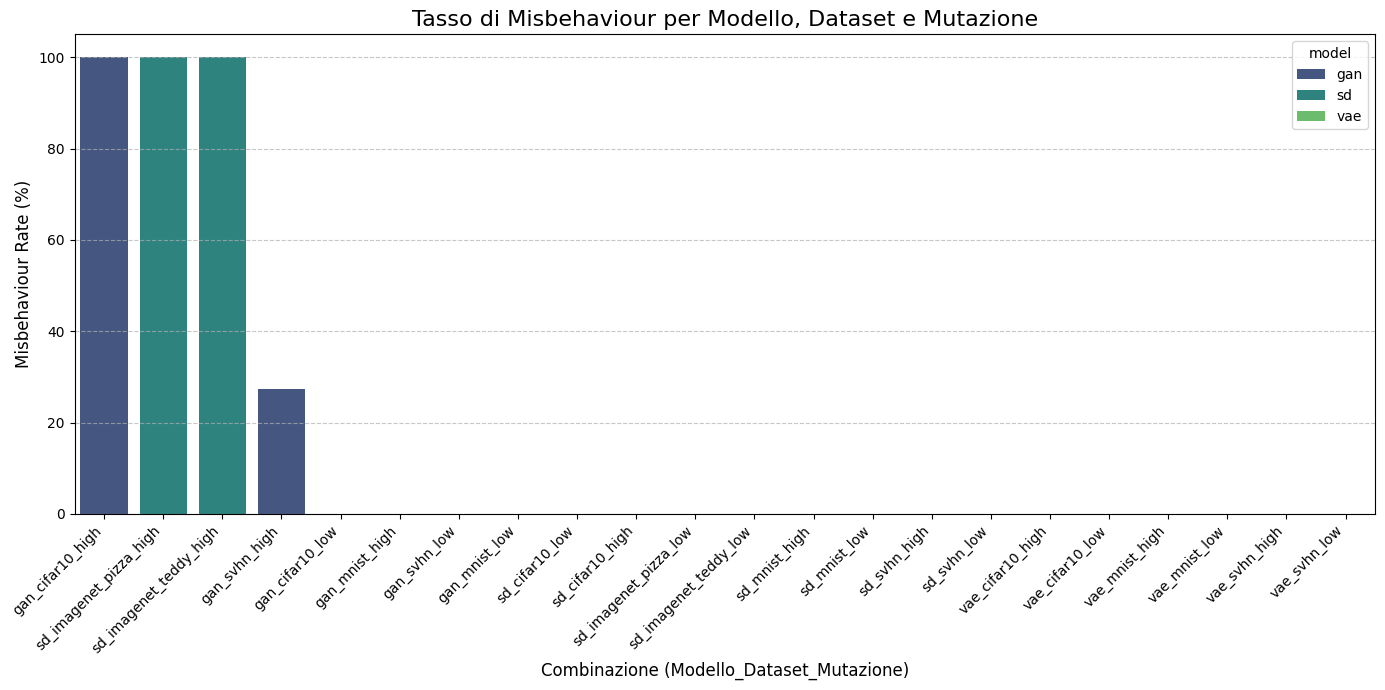


--- ESPORTAZIONE COMPLETATA ---
Risultati completi salvati in: /content/drive/MyDrive/genai_tigs_results/aggregated_full_results.csv
Statistiche aggregate salvate in: /content/drive/MyDrive/genai_tigs_results/aggregated_model_stats.csv


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Creazione del grafico a barre
plt.figure(figsize=(14, 7))

# Creiamo una colonna combinata per l'asse X per migliorare la leggibilità
model_stats['experiment_group'] = model_stats['model'] + '_' + model_stats['dataset'] + '_' + model_stats['mutation']

# Ordiniamo i dati dal tasso di errore più alto al più basso
plot_data = model_stats.sort_values('misbehaviour_rate (%)', ascending=False)

sns.barplot(
    data=plot_data,
    x='experiment_group',
    y='misbehaviour_rate (%)',
    hue='model',
    dodge=False,
    palette='viridis'
)

plt.title('Tasso di Misbehaviour per Modello, Dataset e Mutazione', fontsize=16)
plt.xlabel('Combinazione (Modello_Dataset_Mutazione)', fontsize=12)
plt.ylabel('Misbehaviour Rate (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Esportazione in CSV
output_dir = '/content/drive/MyDrive/genai_tigs_results'

# Salviamo il dataset completo con tutti i seed
full_results_path = os.path.join(output_dir, 'aggregated_full_results.csv')
df_all.to_csv(full_results_path, index=False)

# Salviamo le statistiche raggruppate
summary_stats_path = os.path.join(output_dir, 'aggregated_model_stats.csv')
model_stats.drop(columns=['experiment_group'], errors='ignore').to_csv(summary_stats_path, index=False)

print("\n--- ESPORTAZIONE COMPLETATA ---")
print(f"Risultati completi salvati in: {full_results_path}")
print(f"Statistiche aggregate salvate in: {summary_stats_path}")